In [ ]:
!pip -q install tensorflow scikit-learn seaborn

import os
import zipfile
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from google.colab import files
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score
)
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras import layers, models, callbacks

warnings.filterwarnings("ignore")
np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow version:", tf.__version__)
print("Libraries loaded successfully.")

TensorFlow version: 2.21.0
Libraries loaded successfully.


In [ ]:
uploaded = files.upload()

zip_path = next(
    (name for name in uploaded if name.lower().endswith(".zip")),
    None
)

if zip_path is None:
    raise ValueError("Please upload your .csv.zip dataset.")

csv_frames = []

with zipfile.ZipFile(zip_path, "r") as archive:
    csv_files = [
        name for name in archive.namelist()
        if name.lower().endswith(".csv")
        and not name.startswith("__MACOSX/")
    ]

    if not csv_files:
        raise ValueError("No CSV files were found inside the ZIP.")

    print("CSV files found:", len(csv_files))

    for filename in csv_files:
        with archive.open(filename) as file:
            part = pd.read_csv(file, low_memory=False)
            # Useful if the ZIP contains separate patient files
            part["_source_file"] = filename
            csv_frames.append(part)

df = pd.concat(csv_frames, ignore_index=True, sort=False)

# Standardize column names
df.columns = [
    str(col).strip().replace(" ", "")
    for col in df.columns
]

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())

Saving sepsis_csv_files.zip to sepsis_csv_files.zip
CSV files found: 20336
Dataset shape: (790215, 42)

Column names:
['HR', 'O2Sat', 'Temp', 'SBP', 'MAP', 'DBP', 'Resp', 'EtCO2', 'BaseExcess', 'HCO3', 'FiO2', 'pH', 'PaCO2', 'SaO2', 'AST', 'BUN', 'Alkalinephos', 'Calcium', 'Chloride', 'Creatinine', 'Bilirubin_direct', 'Glucose', 'Lactate', 'Magnesium', 'Phosphate', 'Potassium', 'Bilirubin_total', 'TroponinI', 'Hct', 'Hgb', 'PTT', 'WBC', 'Fibrinogen', 'Platelets', 'Age', 'Gender', 'Unit1', 'Unit2', 'HospAdmTime', 'ICULOS', 'SepsisLabel', '_source_file']


,HR,O2Sat,Temp,SBP,MAP,DBP,Resp,EtCO2,BaseExcess,HCO3,...,Fibrinogen,Platelets,Age,Gender,Unit1,Unit2,HospAdmTime,ICULOS,SepsisLabel,_source_file
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,35.27,1,NaN,NaN,-16.66,1,0,p012385.csv
1,110.0,100.0,37.56,110.0,80.0,68.0,14.0,NaN,NaN,NaN,...,NaN,NaN,35.27,1,NaN,NaN,-16.66,2,0,p012385.csv
2,108.0,100.0,37.61,113.0,83.0,71.0,14.0,NaN,NaN,NaN,...,NaN,NaN,35.27,1,NaN,NaN,-16.66,3,0,p012385.csv
3,117.0,100.0,NaN,108.0,81.0,70.0,14.5,NaN,NaN,NaN,...,NaN,NaN,35.27,1,NaN,NaN,-16.66,4,0,p012385.csv
4,131.0,99.0,NaN,114.0,89.0,77.0,16.0,NaN,0.0,22.0,...,NaN,219.0,35.27,1,NaN,NaN,-16.66,5,0,p012385.csv


In [ ]:
# Find the sepsis target column
target_candidates = [
    col for col in df.columns
    if col.lower() in ["sepsislabel", "sepsis_label", "sepsis"]
]

if not target_candidates:
    raise ValueError(
        "No sepsis label found. Check the column names printed above."
    )

TARGET = target_candidates[0]

# Remove accidental index columns
df = df.loc[
    :,
    ~df.columns.str.lower().str.startswith("unnamed:")
].copy()

# Convert target labels to 0 and 1
df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")
df = df.dropna(subset=[TARGET]).copy()
df[TARGET] = (df[TARGET] > 0).astype(int)

# Recognized patient/record identifiers
id_candidates = [
    "patient_id", "patientid", "subject_id", "subjectid",
    "stay_id", "record_id", "recordid", "patient"
]

existing_id = next(
    (c for c in df.columns if c.lower() in id_candidates),
    None
)

# Identify a time column, if present
time_candidates = ["Hour", "ICULOS", "hours", "time", "hour"]
time_col = next(
    (c for c in df.columns if c.lower() in [x.lower() for x in time_candidates]),
    None
)

if existing_id:
    df["_patient_group"] = df[existing_id].astype(str)

elif df["_source_file"].nunique() > 1:
    # Assumes each CSV file represents one patient/record.
    df["_patient_group"] = df["_source_file"].astype(str)

elif time_col:
    # Infer patient boundaries when time resets in a concatenated file.
    time_values = pd.to_numeric(df[time_col], errors="coerce")
    resets = time_values.diff().le(0)
    resets.iloc[0] = True
    df["_patient_group"] = resets.cumsum().astype(str)

    print(
        "WARNING: Patient groups were inferred from time resets. "
        "Verify this matches your dataset structure."
    )

else:
    raise ValueError(
        "No patient ID, separate patient files, or usable time column was "
        "found. Do not train a patient-level time-series model until patient "
        "boundaries can be identified."
    )

# Sort rows by patient and time
if time_col:
    df[time_col] = pd.to_numeric(df[time_col], errors="coerce")
    df = df.sort_values(
        ["_patient_group", time_col],
        kind="stable"
    ).reset_index(drop=True)
else:
    df = df.reset_index(drop=True)

print("Target column:", TARGET)
print("Time column:", time_col)
print("Patient/record groups:", df["_patient_group"].nunique())
print("\nMissing values (top 15):")
print(df.isna().sum().sort_values(ascending=False).head(15))

print("\nTarget distribution:")
print(df[TARGET].value_counts())

Target column: SepsisLabel
Time column: ICULOS
Patient/record groups: 20336

Missing values (top 15):
EtCO2               790215
TroponinI           789250
Bilirubin_direct    789033
Fibrinogen          784185
Bilirubin_total     780522
Alkalinephos        778683
AST                 778395
Lactate             763072
PTT                 751909
SaO2                751055
Calcium             750897
Phosphate           750319
Platelets           738716
Creatinine          737728
WBC                 730867
dtype: int64

Target distribution:
SepsisLabel
0    773079
1     17136
Name: count, dtype: int64


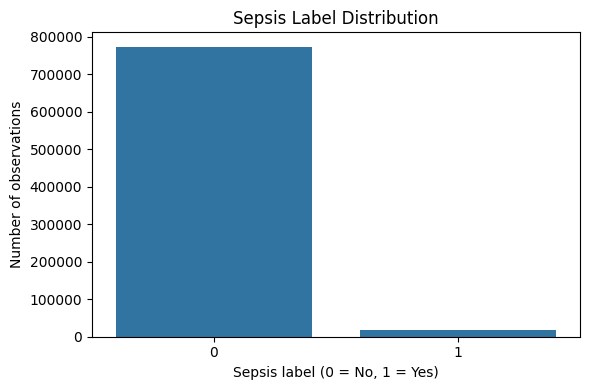

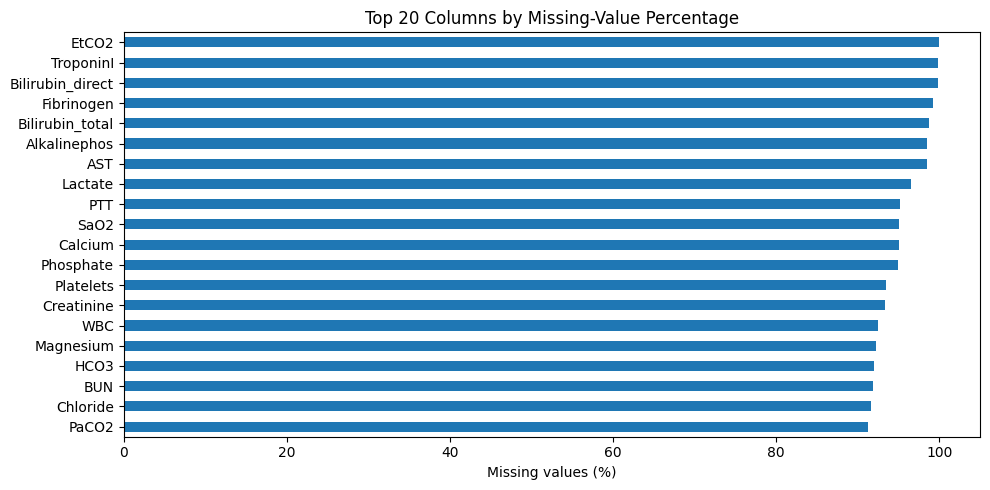

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
HR,729026.0,NaN,NaN,NaN,84.985264,16.940431,20.0,73.0,84.0,96.0,280.0
O2Sat,695136.0,NaN,NaN,NaN,97.265688,2.908794,20.0,96.0,98.0,99.5,100.0
Temp,266901.0,NaN,NaN,NaN,37.026737,0.780317,20.9,36.56,37.06,37.55,42.22
SBP,670014.0,NaN,NaN,NaN,120.962359,21.520567,22.0,105.0,118.5,134.0,281.0
MAP,709357.0,NaN,NaN,NaN,78.767345,15.044038,20.0,68.0,77.0,87.33,300.0
DBP,409918.0,NaN,NaN,NaN,59.985809,12.572771,20.0,51.0,58.5,67.0,298.0
Resp,712957.0,NaN,NaN,NaN,18.77346,5.39575,1.0,15.0,18.0,22.0,69.0
EtCO2,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BaseExcess,82381.0,NaN,NaN,NaN,-0.647537,4.286641,-32.0,-3.0,0.0,1.0,100.0
HCO3,63617.0,NaN,NaN,NaN,24.094476,4.396192,0.0,22.0,24.0,27.0,55.0


In [ ]:
# Target distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x=TARGET)
plt.title("Sepsis Label Distribution")
plt.xlabel("Sepsis label (0 = No, 1 = Yes)")
plt.ylabel("Number of observations")
plt.tight_layout()
plt.show()

# Missing-value percentages
missing_pct = (
    df.isna().mean().mul(100)
    .sort_values(ascending=False)
)
missing_pct = missing_pct[missing_pct > 0].head(20)

if not missing_pct.empty:
    plt.figure(figsize=(10, 5))
    missing_pct.sort_values().plot(kind="barh")
    plt.title("Top 20 Columns by Missing-Value Percentage")
    plt.xlabel("Missing values (%)")
    plt.tight_layout()
    plt.show()

# Dataset summary
display(df.describe(include="all").T.head(30))

In [ ]:
SEQUENCE_LENGTH = 6
FORECAST_HOURS = 6

# Clinical features commonly found in sepsis datasets
preferred_features = [
    "HR", "O2Sat", "Temp", "SBP", "MAP", "DBP", "Resp",
    "EtCO2", "BaseExcess", "HCO3", "FiO2", "pH", "PaCO2",
    "SaO2", "AST", "BUN", "Alkalinephos", "Calcium",
    "Chloride", "Creatinine", "Glucose", "Lactate",
    "Magnesium", "Phosphate", "Potassium", "Hct", "Hgb",
    "WBC", "Fibrinogen", "Platelets", "Age", "Gender",
    "Unit1", "Unit2", "HospAdmTime", "ICULOS"
]

# Keep only features that actually exist
features = [
    col for col in preferred_features
    if col in df.columns
]

# If names differ, use available numeric columns as a fallback
if len(features) < 3:
    excluded = {
        TARGET, "_patient_group", "_source_file"
    }
    if existing_id:
        excluded.add(existing_id)
    if time_col:
        excluded.add(time_col)

    numeric_columns = df.select_dtypes(include=np.number).columns.tolist()
    features = [
        c for c in numeric_columns
        if c not in excluded
    ]

if not features:
    raise ValueError("No usable clinical feature columns were found.")

print("Number of features:", len(features))
print("Features:", features)

# Convert features to numeric
for col in features:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Replace infinite values with missing values
df[features] = df[features].replace([np.inf, -np.inf], np.nan)

# Create sequences within each patient group only
X_list, y_list, group_list = [], [], []

for patient_id, patient in df.groupby("_patient_group", sort=False):
    patient = patient.copy()

    values = patient[features].to_numpy(dtype=np.float32)
    labels = patient[TARGET].to_numpy(dtype=np.int32)

    # Impute missing values within this patient's timeline
    temp = pd.DataFrame(values, columns=features)
    temp = temp.ffill().bfill()

    values = temp.to_numpy(dtype=np.float32)

    # Exclude features that are completely missing in this patient
    # by filling remaining missing values with 0 for now.
    values = np.nan_to_num(
        values, nan=0.0, posinf=0.0, neginf=0.0
    )

    # Input: rows [i-5, ..., i]
    # Target: any sepsis label in rows [i+1, ..., i+6]
    for end in range(SEQUENCE_LENGTH - 1, len(patient) - FORECAST_HOURS):
        start = end - SEQUENCE_LENGTH + 1
        future_end = end + FORECAST_HOURS

        past_labels = labels[start:end + 1]
        future_labels = labels[end + 1:future_end + 1]

        # Early prediction only: patient has not yet developed sepsis
        if past_labels.max() != 0:
            continue

        X_list.append(values[start:end + 1])
        y_list.append(int(future_labels.max() > 0))
        group_list.append(patient_id)

if not X_list:
    raise ValueError(
        "No sequences were generated. Check your time ordering, label "
        "column, patient groups, and dataset length."
    )

X = np.asarray(X_list, dtype=np.float32)
y = np.asarray(y_list, dtype=np.int32)
groups = np.asarray(group_list)

print("Sequence data shape:", X.shape)
print("Labels shape:", y.shape)
print("Positive future-sepsis windows:", int(y.sum()))
print("Negative windows:", int((y == 0).sum()))
print("Unique patient groups in sequences:", len(np.unique(groups)))

if len(np.unique(y)) < 2:
    raise ValueError(
        "The generated sequences contain only one class. Check the target "
        "labels and forecast horizon."
    )

Number of features: 36
Features: ['HR', 'O2Sat', 'Temp', 'SBP', 'MAP', 'DBP', 'Resp', 'EtCO2', 'BaseExcess', 'HCO3', 'FiO2', 'pH', 'PaCO2', 'SaO2', 'AST', 'BUN', 'Alkalinephos', 'Calcium', 'Chloride', 'Creatinine', 'Glucose', 'Lactate', 'Magnesium', 'Phosphate', 'Potassium', 'Hct', 'Hgb', 'WBC', 'Fibrinogen', 'Platelets', 'Age', 'Gender', 'Unit1', 'Unit2', 'HospAdmTime', 'ICULOS']
Sequence data shape: (561792, 6, 36)
Labels shape: (561792,)
Positive future-sepsis windows: 7800
Negative windows: 553992
Unique patient groups in sequences: 19738


=== Dataset Splits ===
Train shape: (448537, 6, 36), Positive labels: 6239 (1.39%)
Val shape:   (113255, 6, 36), Positive labels: 1561 (1.38%)

Computed class weights: {0: np.float64(0.5070529371600143), 1: np.float64(35.946225356627664)}


Model: "Sepsis_LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 6, 36)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 6, 128)         │        51,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 6, 128)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 64)             │        41,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 95,041 (371.25 KB)

 Trainable params: 95,041 (371.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
877/877 ━━━━━━━━━━━━━━━━━━━━ 48s 50ms/step - accuracy: 0.7474 - auc: 0.8359 - loss: 0.4999 - val_accuracy: 0.7404 - val_auc: 0.8227 - val_loss: 0.4928 - learning_rate: 0.0010
Epoch 2/15
877/877 ━━━━━━━━━━━━━━━━━━━━ 84s 53ms/step - accuracy: 0.7830 - auc: 0.8955 - loss: 0.3985 - val_accuracy: 0.7599 - val_auc: 0.8091 - val_loss: 0.4443 - learning_rate: 0.0010
Epoch 3/15
877/877 ━━━━━━━━━━━━━━━━━━━━ 80s 50ms/step - accuracy: 0.8166 - auc: 0.9300 - loss: 0.3145 - val_accuracy: 0.8058 - val_auc: 0.8019 - val_loss: 0.4122 - learning_rate: 0.0010
Epoch 4/15
877/877 ━━━━━━━━━━━━━━━━━━━━ 44s 50ms/step - accuracy: 0.8499 - auc: 0.9502 - loss: 0.2582 - val_accuracy: 0.8397 - val_auc: 0.7846 - val_loss: 0.3628 - learning_rate: 0.0010
Epoch 5/15
877/877 ━━━━━━━━━━━━━━━━━━━━ 44s 50ms/step - accuracy: 0.8755 - auc: 0.9621 - loss: 0.2186 - val_accuracy: 0.8502 - val_auc: 0.7807 - val_loss: 0.3405 - learning_rate: 0.0010
111/111 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step

=== Classification Report (

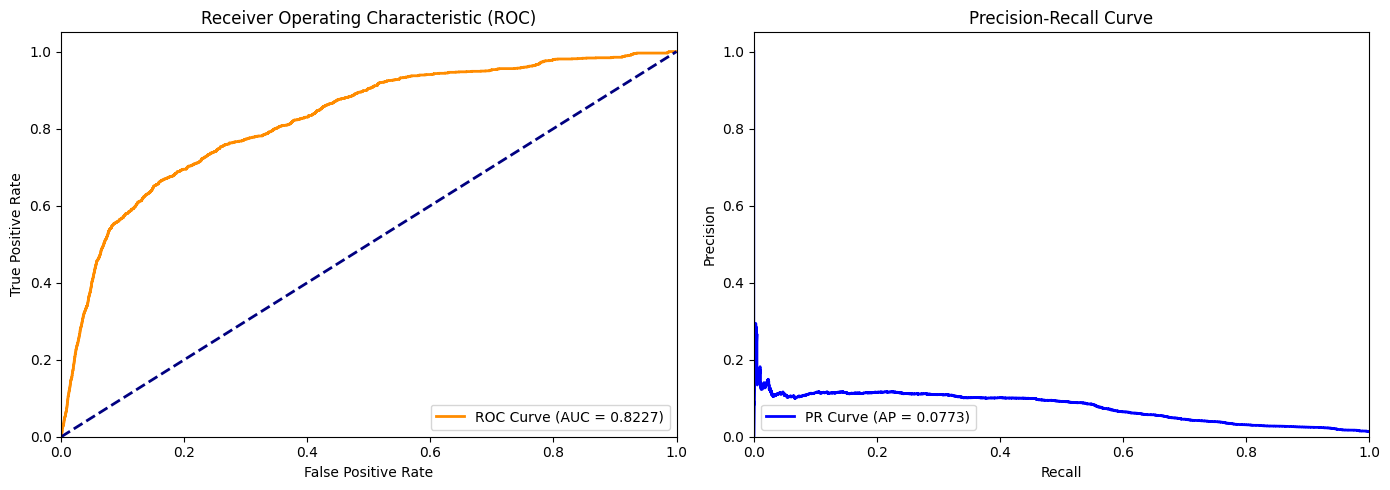

In [ ]:
# 1. Patient-level Train-Validation Split
gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_idx, val_idx = next(gss.split(X, y, groups=groups))

X_train, X_val = X[train_idx], X[val_idx]
y_train, y_val = y[train_idx], y[val_idx]
groups_train, groups_val = groups[train_idx], groups[val_idx]

print("=== Dataset Splits ===")
print(f"Train shape: {X_train.shape}, Positive labels: {int(y_train.sum())} ({y_train.mean()*100:.2f}%)")
print(f"Val shape:   {X_val.shape}, Positive labels: {int(y_val.sum())} ({y_val.mean()*100:.2f}%)")

# 2. Reshape & Standardize temporal features
num_instances_train, seq_len, num_feats = X_train.shape
num_instances_val, _, _ = X_val.shape

scaler = StandardScaler()
X_train_reshaped = X_train.reshape(-1, num_feats)
X_val_reshaped = X_val.reshape(-1, num_feats)

X_train_scaled = scaler.fit_transform(X_train_reshaped).reshape(num_instances_train, seq_len, num_feats)
X_val_scaled = scaler.transform(X_val_reshaped).reshape(num_instances_val, seq_len, num_feats)

# 3. Handle Class Imbalance using Class Weights
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)
class_weight_dict = {i: w for i, w in enumerate(class_weights)}
print(f"\nComputed class weights: {class_weight_dict}")

# 4. Build Bidirectional LSTM Architecture
def build_lstm_model(input_shape):
    inputs = layers.Input(shape=input_shape)
    x = layers.Bidirectional(layers.LSTM(64, return_sequences=True))(inputs)
    x = layers.Dropout(0.3)(x)
    x = layers.Bidirectional(layers.LSTM(32, return_sequences=False))(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(32, activation="relu")(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)

    model = models.Model(inputs=inputs, outputs=outputs, name="Sepsis_LSTM")
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="binary_crossentropy",
        metrics=[tf.keras.metrics.AUC(name="auc"), "accuracy"]
    )
    return model

model = build_lstm_model((seq_len, num_feats))
model.summary()

# 5. Define Training Callbacks & Fit Model
model_callbacks = [
    callbacks.EarlyStopping(
        monitor="val_auc",
        patience=4,
        mode="max",
        restore_best_weights=True
    ),
    callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        verbose=1
    )
]

history = model.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=15,
    batch_size=512,
    class_weight=class_weight_dict,
    callbacks=model_callbacks,
    verbose=1
)

# 6. Make Predictions and Evaluate Model Performance
y_pred_prob = model.predict(X_val_scaled, batch_size=1024).ravel()
y_pred_class = (y_pred_prob >= 0.5).astype(int)

print("\n=== Classification Report (Threshold = 0.5) ===")
print(classification_report(y_val, y_pred_class))

# Plot Model Performance Curves
val_auc = roc_auc_score(y_val, y_pred_prob)
val_ap = average_precision_score(y_val, y_pred_prob)

fpr, tpr, _ = roc_curve(y_val, y_pred_prob)
precision, recall, _ = precision_recall_curve(y_val, y_pred_prob)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# ROC Curve
ax[0].plot(fpr, tpr, color="darkorange", lw=2, label=f"ROC Curve (AUC = {val_auc:.4f})")
ax[0].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
ax[0].set_xlim([0.0, 1.0])
ax[0].set_ylim([0.0, 1.05])
ax[0].set_xlabel("False Positive Rate")
ax[0].set_ylabel("True Positive Rate")
ax[0].set_title("Receiver Operating Characteristic (ROC)")
ax[0].legend(loc="lower right")

# Precision-Recall Curve
ax[1].plot(recall, precision, color="blue", lw=2, label=f"PR Curve (AP = {val_ap:.4f})")
ax[1].set_xlim([0.0, 1.0])
ax[1].set_ylim([0.0, 1.05])
ax[1].set_xlabel("Recall")
ax[1].set_ylabel("Precision")
ax[1].set_title("Precision-Recall Curve")
ax[1].legend(loc="lower left")

plt.tight_layout()
plt.show()

In [ ]:
# Evaluate the model's final metrics on the validation partition
y_pred_prob = model.predict(X_val_scaled, batch_size=1024).ravel()
y_pred_class = (y_pred_prob >= 0.5).astype(int)

print("=== FINAL MODEL METRICS ===")
val_auc = roc_auc_score(y_val, y_pred_prob)
val_ap = average_precision_score(y_val, y_pred_prob)

print(f"Validation Area Under ROC Curve (AUC-ROC): {val_auc:.4f}")
print(f"Validation Average Precision (PR-AUC):     {val_ap:.4f}")

print("\n=== CLASSIFICATION REPORT ===")
print(classification_report(y_val, y_pred_class, target_names=["No Sepsis", "Sepsis (Future onset 1-6h)"]))

111/111 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step
=== FINAL MODEL METRICS ===
Validation Area Under ROC Curve (AUC-ROC): 0.8227
Validation Average Precision (PR-AUC):     0.0773

=== CLASSIFICATION REPORT ===
                            precision    recall  f1-score   support

                 No Sepsis       1.00      0.74      0.85    111694
Sepsis (Future onset 1-6h)       0.04      0.75      0.07      1561

                  accuracy                           0.74    113255
                 macro avg       0.52      0.75      0.46    113255
              weighted avg       0.98      0.74      0.84    113255



In [ ]:
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("Training patients:", len(np.unique(groups[train_idx])))
print("Testing patients:", len(np.unique(groups[test_idx])))

print("\nTraining label counts:")
print(pd.Series(y_train).value_counts())

print("\nTesting label counts:")
print(pd.Series(y_test).value_counts())

if len(np.unique(y_train)) < 2 or len(np.unique(y_test)) < 2:
    raise ValueError(
        "One split contains only one class. The dataset may have too few "
        "patients with positive future-sepsis windows. Review patient "
        "grouping or adjust the split strategy."
    )

Training shape: (448537, 6, 36)
Testing shape: (113255, 6, 36)
Training patients: 15790
Testing patients: 3948

Training label counts:
0    442298
1      6239
Name: count, dtype: int64

Testing label counts:
0    111694
1      1561
Name: count, dtype: int64


In [ ]:
n_features = X_train.shape[2]

scaler = StandardScaler()

X_train_flat = X_train.reshape(-1, n_features)
X_test_flat = X_test.reshape(-1, n_features)

scaler.fit(X_train_flat)

X_train = scaler.transform(X_train_flat).reshape(X_train.shape)
X_test = scaler.transform(X_test_flat).reshape(X_test.shape)

# Keep values within a reasonable range for training stability
X_train = np.clip(X_train, -10, 10).astype(np.float32)
X_test = np.clip(X_test, -10, 10).astype(np.float32)

print("Normalization completed.")
print("CNN input shape:", X_train.shape)

Normalization completed.
CNN input shape: (448537, 6, 36)


In [ ]:
model = models.Sequential([
    layers.Input(shape=(SEQUENCE_LENGTH, n_features)),
    layers.Conv1D(
        filters=64,
        kernel_size=3,
        padding="same",
        activation="relu"
    ),
    layers.BatchNormalization(),
    layers.Dropout(0.25),
    layers.Conv1D(
        filters=128,
        kernel_size=3,
        padding="same",
        activation="relu"
    ),
    layers.BatchNormalization(),
    layers.GlobalAveragePooling1D(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.30),
    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.AUC(name="roc_auc"),
        tf.keras.metrics.AUC(name="pr_auc", curve="PR"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

model.summary()

# Account for class imbalance
classes = np.unique(y_train)
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)
class_weights = dict(zip(classes, weights))

early_stop = callbacks.EarlyStopping(
    monitor="val_pr_auc",
    mode="max",
    patience=5,
    restore_best_weights=True
)

reduce_lr = callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6
)

history = model.fit(
    X_train,
    y_train,
    validation_split=0.20,
    epochs=30,
    batch_size=256,
    class_weight=class_weights,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

print("Training completed.")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 6, 64)          │         6,976 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 6, 64)          │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 6, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 6, 128)         │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 6, 128)         │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 40,769 (159.25 KB)

 Trainable params: 40,385 (157.75 KB)

 Non-trainable params: 384 (1.50 KB)

Epoch 1/30
1402/1402 ━━━━━━━━━━━━━━━━━━━━ 23s 15ms/step - accuracy: 0.7159 - loss: 0.5242 - pr_auc: 0.0644 - precision: 0.0379 - recall: 0.7816 - roc_auc: 0.8241 - val_accuracy: 0.7766 - val_loss: 0.4476 - val_pr_auc: 0.0603 - val_precision: 0.0373 - val_recall: 0.6546 - val_roc_auc: 0.7892 - learning_rate: 0.0010
Epoch 2/30
1402/1402 ━━━━━━━━━━━━━━━━━━━━ 19s 14ms/step - accuracy: 0.7627 - loss: 0.4394 - pr_auc: 0.0905 - precision: 0.0485 - recall: 0.8472 - roc_auc: 0.8777 - val_accuracy: 0.7973 - val_loss: 0.4106 - val_pr_auc: 0.0536 - val_precision: 0.0407 - val_recall: 0.6494 - val_roc_auc: 0.7860 - learning_rate: 0.0010
Epoch 3/30
1402/1402 ━━━━━━━━━━━━━━━━━━━━ 20s 14ms/step - accuracy: 0.7879 - loss: 0.3864 - pr_auc: 0.1109 - precision: 0.0562 - recall: 0.8856 - roc_auc: 0.9039 - val_accuracy: 0.8121 - val_loss: 0.3761 - val_pr_auc: 0.0463 - val_precision: 0.0412 - val_recall: 0.6064 - val_roc_auc: 0.7783 - learning_rate: 0.0010
Epoch 4/30
1402/1402 ━━━━━━━━━━━━━━━━━━━━ 20s 14ms/s

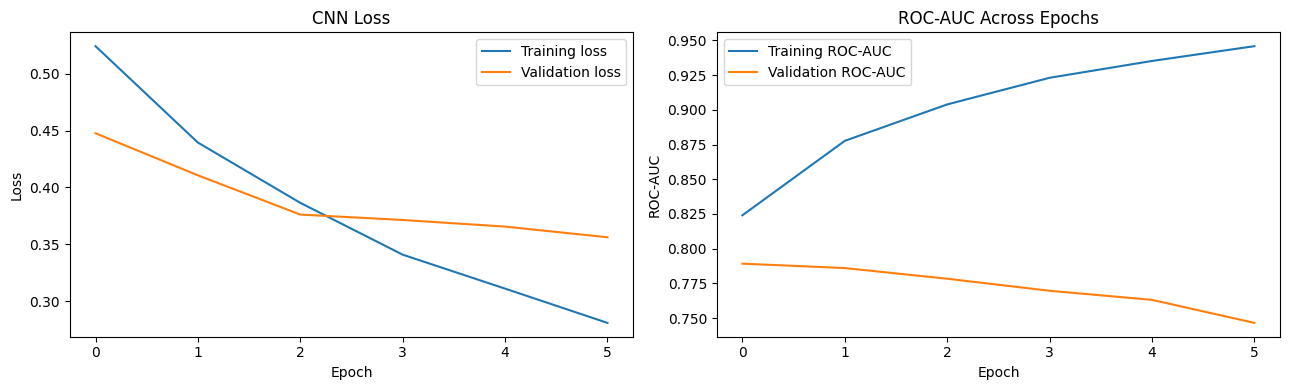

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(history.history["loss"], label="Training loss")
axes[0].plot(history.history["val_loss"], label="Validation loss")
axes[0].set_title("CNN Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(history.history["roc_auc"], label="Training ROC-AUC")
axes[1].plot(history.history["val_roc_auc"], label="Validation ROC-AUC")
axes[1].set_title("ROC-AUC Across Epochs")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("ROC-AUC")
axes[1].legend()

plt.tight_layout()
plt.show()

Test metrics:
loss: 0.4297
compile_metrics: 0.7839

Classification Report:
                          precision    recall  f1-score   support

No sepsis within 6 hours       0.99      0.79      0.88    111694
   Sepsis within 6 hours       0.04      0.67      0.08      1561

                accuracy                           0.78    113255
               macro avg       0.52      0.73      0.48    113255
            weighted avg       0.98      0.78      0.87    113255

ROC-AUC: 0.8043
PR-AUC: 0.0713


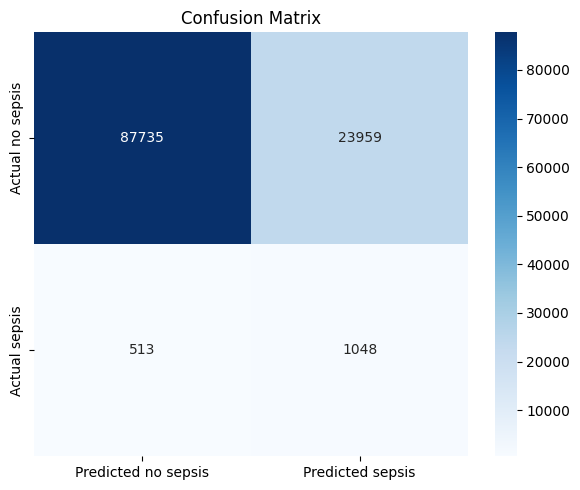

In [ ]:
test_results = model.evaluate(X_test, y_test, verbose=0)

print("Test metrics:")
for name, value in zip(model.metrics_names, test_results):
    print(f"{name}: {value:.4f}")

y_prob = model.predict(X_test, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["No sepsis within 6 hours", "Sepsis within 6 hours"],
        zero_division=0
    )
)

print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))
print("PR-AUC:", round(average_precision_score(y_test, y_prob), 4))

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted no sepsis", "Predicted sepsis"],
    yticklabels=["Actual no sepsis", "Actual sepsis"]
)
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
fpr, tpr, _ = roc_curve(y_test, y_prob)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc_score(y_test, y_prob):.3f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.tight_layout()
plt.show()

precision, recall, _ = precision_recall_curve(y_test, y_prob)

plt.figure(figsize=(6, 5))
plt.plot(
    recall,
    precision,
    label=f"PR-AUC = {average_precision_score(y_test, y_prob):.3f}"
)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
baseline_auc = roc_auc_score(y_test, y_prob)
importance_results = []

for i, feature in enumerate(features):
    X_masked = X_test.copy()

    # Standardized zero represents the training-set mean
    X_masked[:, :, i] = 0.0

    masked_prob = model.predict(X_masked, verbose=0).ravel()
    masked_auc = roc_auc_score(y_test, masked_prob)

    importance_results.append({
        "Feature": feature,
        "Baseline ROC-AUC": baseline_auc,
        "ROC-AUC after masking": masked_auc,
        "Importance (AUC drop)": baseline_auc - masked_auc
    })

importance_df = pd.DataFrame(importance_results)
importance_df = importance_df.sort_values(
    "Importance (AUC drop)",
    ascending=False
)

display(importance_df)

plt.figure(figsize=(10, 7))
sns.barplot(
    data=importance_df.head(15),
    x="Importance (AUC drop)",
    y="Feature"
)
plt.title("Top 15 Features by CNN Ablation Importance")
plt.xlabel("Decrease in ROC-AUC after masking")
plt.tight_layout()
plt.show()

In [ ]:
import joblib
import json
from google.colab import files

model.save("/content/sepsis_cnn_model.keras")
joblib.dump(scaler, "/content/sepsis_scaler.pkl")

with open("/content/sepsis_features.json", "w") as f:
    json.dump(features, f, indent=2)

importance_df.to_csv(
    "/content/sepsis_feature_importance.csv",
    index=False
)

print("Saved:")
print("- sepsis_cnn_model.keras")
print("- sepsis_scaler.pkl")
print("- sepsis_features.json")
print("- sepsis_feature_importance.csv")

files.download("/content/sepsis_cnn_model.keras")
files.download("/content/sepsis_scaler.pkl")
files.download("/content/sepsis_features.json")
files.download("/content/sepsis_feature_importance.csv")

Saved:
- sepsis_cnn_model.keras
- sepsis_scaler.pkl
- sepsis_features.json
- sepsis_feature_importance.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import json
import numpy as np

scaler_data = {
    "mean": scaler.mean_.tolist(),
    "scale": scaler.scale_.tolist(),
    "features": features
}

with open("/content/sepsis_scaler.json", "w") as f:
    json.dump(scaler_data, f, indent=2)

from google.colab import files
files.download("/content/sepsis_scaler.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import zipfile
import pandas as pd
from google.colab import files

# Fixed the filename from 'sepsi_csv_files.csv.zip' to 'sepsis_csv_files.zip'
zip_path = "/content/sepsis_csv_files.zip"

with zipfile.ZipFile(zip_path) as z:
    csv_name = next(
        n for n in z.namelist()
        if n.lower().endswith(".csv")
    )
    with z.open(csv_name) as f:
        df = pd.read_csv(f, nrows=2000)

df.to_csv("/content/sepsis_sample.csv", index=False)
files.download("/content/sepsis_sample.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os
import zipfile
import pandas as pd
import numpy as np
from google.colab import files

uploaded = files.upload()
zip_path = next(
    (name for name in uploaded if name.lower().endswith(".zip")),
    None
)

if zip_path is None:
    raise ValueError("Upload your .zip dataset file.")

with zipfile.ZipFile(zip_path, "r") as z:
    csv_files = [
        name for name in z.namelist()
        if name.lower().endswith(".csv")
        and not name.startswith("__MACOSX/")
    ]

    if not csv_files:
        raise ValueError("No CSV files were found inside the ZIP.")

    frames = []

    for name in csv_files:
        with z.open(name) as f:
            temp = pd.read_csv(f, low_memory=False)

        # If the ZIP contains separate patient CSVs and no patient
        # identifier, use the filename as the patient identifier.
        if len(csv_files) > 1 and not any(
            c.lower() in [
                "patient_id", "patientid", "subject_id",
                "subjectid", "person_id", "stay_id"
            ]
            for c in temp.columns
        ):
            temp["Patient_ID"] = name

        frames.append(temp)

df = pd.concat(frames, ignore_index=True)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nFirst five rows:")
display(df.head())
print("\nMissing values, top 20:")
display(df.isnull().sum().sort_values(ascending=False).head(20))

Saving sepsis_csv_files (1).zip to sepsis_csv_files (1).zip
Dataset shape: (790215, 42)

Column names:
['HR', 'O2Sat', 'Temp', 'SBP', 'MAP', 'DBP', 'Resp', 'EtCO2', 'BaseExcess', 'HCO3', 'FiO2', 'pH', 'PaCO2', 'SaO2', 'AST', 'BUN', 'Alkalinephos', 'Calcium', 'Chloride', 'Creatinine', 'Bilirubin_direct', 'Glucose', 'Lactate', 'Magnesium', 'Phosphate', 'Potassium', 'Bilirubin_total', 'TroponinI', 'Hct', 'Hgb', 'PTT', 'WBC', 'Fibrinogen', 'Platelets', 'Age', 'Gender', 'Unit1', 'Unit2', 'HospAdmTime', 'ICULOS', 'SepsisLabel', 'Patient_ID']

First five rows:


,HR,O2Sat,Temp,SBP,MAP,DBP,Resp,EtCO2,BaseExcess,HCO3,...,Fibrinogen,Platelets,Age,Gender,Unit1,Unit2,HospAdmTime,ICULOS,SepsisLabel,Patient_ID
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,35.27,1,NaN,NaN,-16.66,1,0,p012385.csv
1,110.0,100.0,37.56,110.0,80.0,68.0,14.0,NaN,NaN,NaN,...,NaN,NaN,35.27,1,NaN,NaN,-16.66,2,0,p012385.csv
2,108.0,100.0,37.61,113.0,83.0,71.0,14.0,NaN,NaN,NaN,...,NaN,NaN,35.27,1,NaN,NaN,-16.66,3,0,p012385.csv
3,117.0,100.0,NaN,108.0,81.0,70.0,14.5,NaN,NaN,NaN,...,NaN,NaN,35.27,1,NaN,NaN,-16.66,4,0,p012385.csv
4,131.0,99.0,NaN,114.0,89.0,77.0,16.0,NaN,0.0,22.0,...,NaN,219.0,35.27,1,NaN,NaN,-16.66,5,0,p012385.csv



Missing values, top 20:


,0
EtCO2,790215
TroponinI,789250
Bilirubin_direct,789033
Fibrinogen,784185
Bilirubin_total,780522
Alkalinephos,778683
AST,778395
Lactate,763072
PTT,751909
SaO2,751055


In [ ]:
# Change these manually if automatic detection selects the wrong column.
PATIENT_COL = None       # Example: "Patient_ID"
TARGET_COL = None        # Example: "SepsisLabel"
TIME_COL = None          # Example: "Hour"

def find_column(data, candidates):
    lookup = {c.lower().strip(): c for c in data.columns}
    for candidate in candidates:
        if candidate.lower() in lookup:
            return lookup[candidate.lower()]
    return None

if PATIENT_COL is None:
    PATIENT_COL = find_column(df, [
        "Patient_ID", "patient_id", "PatientID",
        "subject_id", "SubjectID", "stay_id", "ICUStayID"
    ])

if TARGET_COL is None:
    TARGET_COL = find_column(df, [
        "SepsisLabel", "sepsis_label", "sepsis",
        "Sepsis", "target", "label"
    ])

if TIME_COL is None:
    TIME_COL = find_column(df, [
        "Hour", "hour", "ICULOS", "time",
        "timestamp", "Time"
    ])

print("Patient column:", PATIENT_COL)
print("Target column:", TARGET_COL)
print("Time column:", TIME_COL)

if PATIENT_COL is None:
    raise ValueError(
        "No patient ID was found. Do not randomly split rows or infer "
        "patient boundaries without checking the dataset structure."
    )

if TARGET_COL is None:
    raise ValueError(
        "No sepsis target was found. Set TARGET_COL to the correct column."
    )

print("\nTarget values:")
print(df[TARGET_COL].value_counts(dropna=False))

Patient column: Patient_ID
Target column: SepsisLabel
Time column: ICULOS

Target values:
SepsisLabel
0    773079
1     17136
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import GroupShuffleSplit

# Convert the target into binary 0/1 labels.
target_numeric = pd.to_numeric(df[TARGET_COL], errors="coerce")

if target_numeric.notna().all() and set(target_numeric.unique()).issubset({0, 1}):
    df[TARGET_COL] = target_numeric.astype(int)
else:
    raise ValueError(
        "The target is not binary 0/1. Inspect df[TARGET_COL].value_counts() "
        "and map the correct negative and positive labels explicitly."
    )

df = df.dropna(subset=[PATIENT_COL, TARGET_COL]).copy()
df[TARGET_COL] = df[TARGET_COL].astype(int)

# Remove rows with invalid feature values later; preserve patient boundaries.
df = df.sort_values([PATIENT_COL] + ([TIME_COL] if TIME_COL else []))

# Exclude target, identifiers, and time from predictive features.
excluded = {PATIENT_COL, TARGET_COL}
if TIME_COL:
    excluded.add(TIME_COL)

# Avoid common identifiers and leakage-prone columns.
for col in df.columns:
    lower = col.lower()
    if (
        lower in {"id", "patientid", "patient_id", "subject_id",
                  "stay_id", "icustayid"}
        or lower.endswith("_id")
    ):
        excluded.add(col)

feature_cols = [
    c for c in df.columns
    if c not in excluded
    and pd.api.types.is_numeric_dtype(df[c])
]

if not feature_cols:
    raise ValueError("No numeric clinical features were found.")

# Convert feature columns to numeric and replace infinities.
df[feature_cols] = df[feature_cols].apply(
    pd.to_numeric, errors="coerce"
)
df[feature_cols] = df[feature_cols].replace(
    [np.inf, -np.inf], np.nan
)

# Split unique patients: 70% train, 15% validation, 15% test.
groups = df[PATIENT_COL].drop_duplicates().to_numpy()

split1 = GroupShuffleSplit(
    n_splits=1, test_size=0.30, random_state=42
)
train_idx, remaining_idx = next(
    split1.split(groups, groups=groups)
)
train_patients = set(groups[train_idx])
remaining_patients = groups[remaining_idx]

split2 = GroupShuffleSplit(
    n_splits=1, test_size=0.50, random_state=42
)
val_idx, test_idx = next(
    split2.split(remaining_patients, groups=remaining_patients)
)
val_patients = set(remaining_patients[val_idx])
test_patients = set(remaining_patients[test_idx])

train_df = df[df[PATIENT_COL].isin(train_patients)].copy()
val_df = df[df[PATIENT_COL].isin(val_patients)].copy()
test_df = df[df[PATIENT_COL].isin(test_patients)].copy()

print("Patients:", len(train_patients), len(val_patients), len(test_patients))
print("Rows:", len(train_df), len(val_df), len(test_df))
print("Features:", feature_cols)
print("Training positive-label rate:", train_df[TARGET_COL].mean())
print("Validation positive-label rate:", val_df[TARGET_COL].mean())
print("Test positive-label rate:", test_df[TARGET_COL].mean())

Patients: 14235 3050 3051
Rows: 551588 117945 120682
Features: ['HR', 'O2Sat', 'Temp', 'SBP', 'MAP', 'DBP', 'Resp', 'EtCO2', 'BaseExcess', 'HCO3', 'FiO2', 'pH', 'PaCO2', 'SaO2', 'AST', 'BUN', 'Alkalinephos', 'Calcium', 'Chloride', 'Creatinine', 'Bilirubin_direct', 'Glucose', 'Lactate', 'Magnesium', 'Phosphate', 'Potassium', 'Bilirubin_total', 'TroponinI', 'Hct', 'Hgb', 'PTT', 'WBC', 'Fibrinogen', 'Platelets', 'Age', 'Gender', 'Unit1', 'Unit2', 'HospAdmTime']
Training positive-label rate: 0.021871396767152294
Validation positive-label rate: 0.020501081012336258
Test positive-label rate: 0.02199168061517045


In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Fit preprocessing ONLY on training rows.
imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()

X_train_raw = imputer.fit_transform(train_df[feature_cols])
X_val_raw = imputer.transform(val_df[feature_cols])
X_test_raw = imputer.transform(test_df[feature_cols])

X_train_scaled = scaler.fit_transform(X_train_raw)
X_val_scaled = scaler.transform(X_val_raw)
X_test_scaled = scaler.transform(X_test_raw)

# Add indicators for features that were originally missing.
# Fit the feature selection on training data, then use the same columns.
missing_cols = [
    c for c in feature_cols
    if train_df[c].isna().any()
]

if missing_cols:
    train_missing = train_df[missing_cols].isna().astype(np.float32).to_numpy()
    val_missing = val_df[missing_cols].isna().astype(np.float32).to_numpy()
    test_missing = test_df[missing_cols].isna().astype(np.float32).to_numpy()

    X_train_scaled = np.concatenate(
        [X_train_scaled, train_missing], axis=1
    )
    X_val_scaled = np.concatenate(
        [X_val_scaled, val_missing], axis=1
    )
    X_test_scaled = np.concatenate(
        [X_test_scaled, test_missing], axis=1
    )

model_features = feature_cols + [
    f"{c}_missing" for c in missing_cols
]

print("Final input features:", len(model_features))
print("Training matrix:", X_train_scaled.shape)

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['EtCO2']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['EtCO2']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['EtCO2']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


Final input features: 76
Training matrix: (551588, 75)


In [ ]:
INPUT_HOURS = 6
PREDICTION_HOURS = 6

def make_sequences(partition_df, scaled_features):
    X, y, patient_groups = [], [], []
    offset = 0

    for patient, patient_df in partition_df.groupby(
        PATIENT_COL, sort=False
    ):
        patient_df = patient_df.reset_index(drop=True)
        n = len(patient_df)

        # The scaled rows follow the same row order as partition_df.
        patient_scaled = scaled_features[offset:offset + n]
        offset += n

        labels = patient_df[TARGET_COL].to_numpy(dtype=int)

        # Input window: [t, t+6)
        # Target window: [t+6, t+12)
        for start in range(n - INPUT_HOURS - PREDICTION_HOURS + 1):
            middle = start + INPUT_HOURS
            end = middle + PREDICTION_HOURS

            past_labels = labels[start:middle]
            future_labels = labels[middle:end]

            # Do not predict new onset from an already-positive window.
            if past_labels.max() == 1:
                continue

            X.append(patient_scaled[start:middle])
            y.append(int(future_labels.max() == 1))
            patient_groups.append(patient)

    if not X:
        raise ValueError(
            "No sequences were created. Check patient lengths, labels, "
            "and the hourly sampling assumption."
        )

    return (
        np.asarray(X, dtype=np.float32),
        np.asarray(y, dtype=np.int32),
        np.asarray(patient_groups)
    )

X_train, y_train, g_train = make_sequences(train_df, X_train_scaled)
X_val, y_val, g_val = make_sequences(val_df, X_val_scaled)
X_test, y_test, g_test = make_sequences(test_df, X_test_scaled)

print("Train:", X_train.shape, "Positive rate:", y_train.mean())
print("Validation:", X_val.shape, "Positive rate:", y_val.mean())
print("Test:", X_test.shape, "Positive rate:", y_test.mean())

print("\nTraining labels:", np.unique(y_train, return_counts=True))
print("Validation labels:", np.unique(y_val, return_counts=True))
print("Test labels:", np.unique(y_test, return_counts=True))

Train: (391628, 6, 75) Positive rate: 0.013952015688357319
Validation: (83747, 6, 75) Positive rate: 0.013098976679761664
Test: (86417, 6, 75) Positive rate: 0.014337456750407906

Training labels: (array([0, 1], dtype=int32), array([386164,   5464]))
Validation labels: (array([0, 1], dtype=int32), array([82650,  1097]))
Test labels: (array([0, 1], dtype=int32), array([85178,  1239]))


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from sklearn.utils.class_weight import compute_class_weight

tf.keras.utils.set_random_seed(42)

classes = np.unique(y_train)
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)
class_weights = {
    int(c): float(w) for c, w in zip(classes, weights)
}
print("Class weights:", class_weights)

model = models.Sequential([
    layers.Input(shape=(X_train.shape[1], X_train.shape[2])),

    layers.Conv1D(64, kernel_size=3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.SpatialDropout1D(0.20),

    layers.Conv1D(64, kernel_size=3, padding="same", activation="relu"),
    layers.BatchNormalization(),

    layers.GlobalAveragePooling1D(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.35),
    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.AUC(name="roc_auc"),
        tf.keras.metrics.AUC(name="pr_auc", curve="PR"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

early_stop = callbacks.EarlyStopping(
    monitor="val_pr_auc",
    mode="max",
    patience=8,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = callbacks.ReduceLROnPlateau(
    monitor="val_pr_auc",
    mode="max",
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=60,
    batch_size=128,
    class_weight=class_weights,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

model.summary()

Class weights: {0: 0.5070747143700604, 1: 35.837115666178626}
Epoch 1/60
3060/3060 ━━━━━━━━━━━━━━━━━━━━ 40s 11ms/step - loss: 0.6366 - pr_auc: 0.0277 - precision: 0.0235 - recall: 0.6909 - roc_auc: 0.6922 - val_loss: 0.7729 - val_pr_auc: 0.0313 - val_precision: 0.0190 - val_recall: 0.8140 - val_roc_auc: 0.7048 - learning_rate: 0.0010
Epoch 2/60
3060/3060 ━━━━━━━━━━━━━━━━━━━━ 34s 11ms/step - loss: 0.6008 - pr_auc: 0.0356 - precision: 0.0264 - recall: 0.7408 - roc_auc: 0.7369 - val_loss: 0.5939 - val_pr_auc: 0.0317 - val_precision: 0.0236 - val_recall: 0.6955 - val_roc_auc: 0.7122 - learning_rate: 0.0010
Epoch 3/60
3060/3060 ━━━━━━━━━━━━━━━━━━━━ 33s 11ms/step - loss: 0.5823 - pr_auc: 0.0406 - precision: 0.0275 - recall: 0.7707 - roc_auc: 0.7556 - val_loss: 0.5808 - val_pr_auc: 0.0310 - val_precision: 0.0234 - val_recall: 0.6609 - val_roc_auc: 0.7090 - learning_rate: 0.0010
Epoch 4/60
3060/3060 ━━━━━━━━━━━━━━━━━━━━ 34s 11ms/step - loss: 0.5646 - pr_auc: 0.0469 - precision: 0.0284 - recall

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 6, 64)          │        14,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 6, 64)          │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ (None, 6, 64)          │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 6, 64)          │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 6, 64)          │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 94,149 (367.77 KB)

 Trainable params: 31,297 (122.25 KB)

 Non-trainable params: 256 (1.00 KB)

 Optimizer params: 62,596 (244.52 KB)

In [ ]:
from sklearn.metrics import (
    classification_report, confusion_matrix,
    f1_score, precision_score, recall_score,
    roc_auc_score, average_precision_score
)

val_prob = model.predict(X_val, verbose=0).ravel()

thresholds = np.arange(0.05, 0.96, 0.01)
threshold_results = []

for threshold in thresholds:
    pred = (val_prob >= threshold).astype(int)

    threshold_results.append({
        "threshold": float(threshold),
        "precision": precision_score(y_val, pred, zero_division=0),
        "recall": recall_score(y_val, pred, zero_division=0),
        "f1": f1_score(y_val, pred, zero_division=0)
    })

threshold_table = pd.DataFrame(threshold_results)
threshold_table = threshold_table.sort_values(
    "f1", ascending=False
)

display(threshold_table.head(10))

best_threshold = float(threshold_table.iloc[0]["threshold"])
print("Selected validation threshold:", best_threshold)

# Final evaluation on the held-out test patients.
test_prob = model.predict(X_test, verbose=0).ravel()
test_pred = (test_prob >= best_threshold).astype(int)

print("\nClassification report:")
print(classification_report(
    y_test, test_pred,
    target_names=["No Sepsis", "Sepsis"],
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(y_test, test_pred))

if len(np.unique(y_test)) == 2:
    print("Test ROC-AUC:", round(roc_auc_score(y_test, test_prob), 4))
    print("Test PR-AUC:", round(average_precision_score(y_test, test_prob), 4))

print("Test F1:", round(f1_score(y_test, test_pred, zero_division=0), 4))
print("Test precision:", round(
    precision_score(y_test, test_pred, zero_division=0), 4
))
print("Test recall:", round(
    recall_score(y_test, test_pred, zero_division=0), 4
))

,threshold,precision,recall,f1
71,0.76,0.048780,0.149499,0.073559
72,0.77,0.051301,0.129444,0.073480
70,0.75,0.046058,0.167730,0.072270
69,0.74,0.043854,0.189608,0.071233
67,0.72,0.040482,0.238833,0.069230
68,0.73,0.041157,0.208751,0.068758
66,0.71,0.038993,0.262534,0.067901
73,0.78,0.050496,0.102097,0.067572
65,0.70,0.037296,0.287147,0.066017
64,0.69,0.036809,0.316317,0.065945


Selected validation threshold: 0.7600000000000002

Classification report:
              precision    recall  f1-score   support

   No Sepsis       0.99      0.97      0.98     85178
      Sepsis       0.05      0.11      0.07      1239

    accuracy                           0.95     86417
   macro avg       0.52      0.54      0.52     86417
weighted avg       0.97      0.95      0.96     86417

Confusion matrix:
[[82378  2800]
 [ 1099   140]]
Test ROC-AUC: 0.6923
Test PR-AUC: 0.0297
Test F1: 0.067
Test precision: 0.0476
Test recall: 0.113


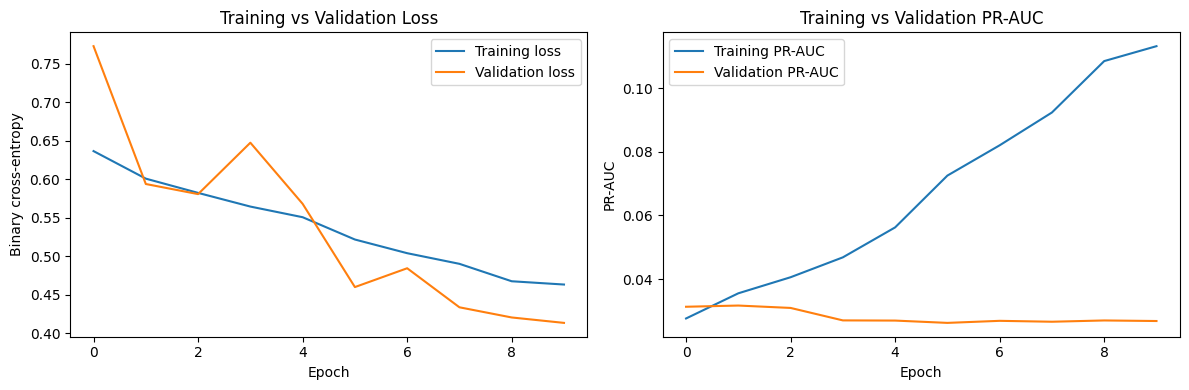

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["loss"], label="Training loss")
axes[0].plot(history.history["val_loss"], label="Validation loss")
axes[0].set_title("Training vs Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary cross-entropy")
axes[0].legend()

axes[1].plot(history.history["pr_auc"], label="Training PR-AUC")
axes[1].plot(history.history["val_pr_auc"], label="Validation PR-AUC")
axes[1].set_title("Training vs Validation PR-AUC")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("PR-AUC")
axes[1].legend()

plt.tight_layout()
plt.show()